In [ ]:
#@title 00. Google Drive 연결 및 결과 저장 경로 설정

from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import unicodedata


MYDRIVE = Path("/content/drive/MyDrive")


def normalized_name(path):
    return unicodedata.normalize(
        "NFC",
        path.name,
    )


macgyver_candidates = [
    path
    for path in MYDRIVE.iterdir()
    if (
        path.is_dir()
        and "[MacGyver]" in normalized_name(path)
        and "최종프로젝트" in normalized_name(path)
    )
]

assert len(macgyver_candidates) >= 1, (
    "MyDrive에서 [MacGyver]최종프로젝트 폴더를 찾지 못했습니다."
)


MACGYVER_ROOT = macgyver_candidates[0]

ANGIOCAD_ROOT = (
    MACGYVER_ROOT
    / "03_data"
    / "AngioCAD"
)

assert ANGIOCAD_ROOT.exists(), (
    f"AngioCAD 폴더를 찾지 못했습니다: {ANGIOCAD_ROOT}"
)


HYUNKYUNG_ROOT = (
    ANGIOCAD_ROOT
    / "hyunkyung"
)

PHASE2_OUTPUT_DIR = (
    HYUNKYUNG_ROOT
    / "02_medsam2_vessel_segmentation"
)

CHECKPOINT_DIR = (
    PHASE2_OUTPUT_DIR
    / "checkpoints"
)

INPUT_SAVE_DIR = (
    PHASE2_OUTPUT_DIR
    / "inputs"
)

MASK_SAVE_DIR = (
    PHASE2_OUTPUT_DIR
    / "masks"
)

OVERLAY_SAVE_DIR = (
    PHASE2_OUTPUT_DIR
    / "overlays"
)

RESULT_SAVE_DIR = (
    PHASE2_OUTPUT_DIR
    / "results"
)


for directory in [
    PHASE2_OUTPUT_DIR,
    CHECKPOINT_DIR,
    INPUT_SAVE_DIR,
    MASK_SAVE_DIR,
    OVERLAY_SAVE_DIR,
    RESULT_SAVE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


print("AngioCAD root:", ANGIOCAD_ROOT)
print("Phase 2 결과:", PHASE2_OUTPUT_DIR)

Mounted at /content/drive
AngioCAD root: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD
Phase 2 결과: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation


In [ ]:
#@title 01. MedSAM2 및 필요 패키지 설치

import sys
import subprocess
from pathlib import Path


MEDSAM2_REPO_DIR = Path(
    "/content/MedSAM2"
)


# unrar 설치
subprocess.run(
    [
        "apt-get",
        "-qq",
        "update",
    ],
    check=True,
)

subprocess.run(
    [
        "apt-get",
        "-qq",
        "install",
        "-y",
        "unrar",
        "rsync",
    ],
    check=True,
)


# MedSAM2 clone
if not (
    MEDSAM2_REPO_DIR
    / ".git"
).exists():

    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/bowang-lab/MedSAM2.git",
            str(MEDSAM2_REPO_DIR),
        ],
        check=True,
    )

else:
    print(
        "기존 MedSAM2 repository를 사용합니다."
    )


# MedSAM2 설치
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-e",
        str(MEDSAM2_REPO_DIR),
    ],
    check=True,
)


# 추가 패키지
subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "huggingface_hub",
        "opencv-python-headless",
    ],
    check=True,
)


print("✅ MedSAM2 설치 완료")

✅ MedSAM2 설치 완료


In [ ]:
#@title 02. 라이브러리 import 및 실험 설정

import os
import re
import sys
import json
import time
import shutil
import subprocess

from pathlib import Path
from contextlib import nullcontext

import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch


assert torch.cuda.is_available(), (
    "GPU 런타임이 아닙니다. "
    "런타임 유형을 NVIDIA L4 GPU로 변경하세요."
)


DEVICE = "cuda"

print("GPU:", torch.cuda.get_device_name(0))
print(
    "BF16 지원:",
    torch.cuda.is_bf16_supported(),
)


# --------------------------------------------------
# 첫 시험 영상
# --------------------------------------------------

PATIENT_ID = 6
SERIES_ID = 7
FRAME_NAME = "frame_0033.png"


# --------------------------------------------------
# Model 정보
# --------------------------------------------------

MODEL_REPO_ID = (
    "Elakiya17/CA-SAM2"
)

MODEL_FILENAME = (
    "medsam2_arcade_v2.pt"
)

MODEL_CONFIG = (
    "configs/sam2.1_hiera_t512.yaml"
)


# --------------------------------------------------
# Colab 로컬 경로
# --------------------------------------------------

LOCAL_RAR_DIR = Path(
    "/content/AngioCAD_RAR_parts"
)

LOCAL_EXTRACT_DIR = Path(
    "/content/AngioCAD_MedSAM2_data"
)

LOCAL_RAR_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

LOCAL_EXTRACT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


experiment_name = (
    f"patient_{PATIENT_ID:03d}"
    f"_series_{SERIES_ID:02d}"
    f"_{Path(FRAME_NAME).stem}"
)

EXPERIMENT_OUTPUT_DIR = (
    RESULT_SAVE_DIR
    / experiment_name
)

EXPERIMENT_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


config = {
    "patient_id": PATIENT_ID,
    "series_id": SERIES_ID,
    "frame_name": FRAME_NAME,
    "model_repository": MODEL_REPO_ID,
    "model_filename": MODEL_FILENAME,
    "model_config": MODEL_CONFIG,
    "device": DEVICE,
    "purpose": (
        "independent coronary vessel segmentation"
    ),
}


with open(
    EXPERIMENT_OUTPUT_DIR
    / "00_experiment_config.json",
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        config,
        file,
        indent=2,
        ensure_ascii=False,
    )


print(
    json.dumps(
        config,
        indent=2,
        ensure_ascii=False,
    )
)

print(
    "실험 저장 폴더:",
    EXPERIMENT_OUTPUT_DIR,
)

GPU: NVIDIA L4
BF16 지원: True
{
  "patient_id": 6,
  "series_id": 7,
  "frame_name": "frame_0033.png",
  "model_repository": "Elakiya17/CA-SAM2",
  "model_filename": "medsam2_arcade_v2.pt",
  "model_config": "configs/sam2.1_hiera_t512.yaml",
  "device": "cuda",
  "purpose": "independent coronary vessel segmentation"
}
실험 저장 폴더: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_07_frame_0033


In [ ]:
#@title 03. RAR에서 선택 프레임 직접 추출 — 최종 단순화 버전

from pathlib import Path
import re
import shutil
import subprocess


# ============================================================
# 1. 선택 설정
# ============================================================

PATIENT_ID = int(
    globals().get("PATIENT_ID", 6)
)

SERIES_ID = int(
    globals().get("SERIES_ID", 7)
)

FRAME_NAME = str(
    globals().get(
        "FRAME_NAME",
        "frame_0033.png",
    )
)

LOCAL_RAR_DIR = Path(
    "/content/AngioCAD_RAR_parts"
)

EXTRACT_ROOT = Path(
    "/content/AngioCAD_MedSAM2_data"
)

LOCAL_RAR_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

EXTRACT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    f"선택 대상: Patient {PATIENT_ID} / "
    f"Series {SERIES_ID} / {FRAME_NAME}"
)


# ============================================================
# 2. 이미 /content에 압축 해제된 이미지가 있는지 확인
# ============================================================

def find_existing_selected_frame():
    candidates = []

    # Google Drive는 검색하지 않고 /content의 로컬 폴더만 확인
    for content_child in Path("/content").iterdir():
        if not content_child.is_dir():
            continue

        if content_child.name == "drive":
            continue

        candidate_patterns = [
            (
                content_child
                / "AngioCAD_Dataset"
                / str(PATIENT_ID)
                / str(SERIES_ID)
                / FRAME_NAME
            ),
            (
                content_child
                / "AngioCAD_Dataset"
                / f"{PATIENT_ID:03d}"
                / str(SERIES_ID)
                / FRAME_NAME
            ),
            (
                content_child
                / "AngioCAD_Dataset"
                / str(PATIENT_ID)
                / f"{SERIES_ID:02d}"
                / FRAME_NAME
            ),
            (
                content_child
                / "AngioCAD_Dataset"
                / f"{PATIENT_ID:03d}"
                / f"{SERIES_ID:02d}"
                / FRAME_NAME
            ),
        ]

        for candidate in candidate_patterns:
            if candidate.is_file():
                candidates.append(candidate)

    # 이번 셀의 추출 폴더 자체도 직접 확인
    direct_candidates = [
        (
            EXTRACT_ROOT
            / "AngioCAD_Dataset"
            / str(PATIENT_ID)
            / str(SERIES_ID)
            / FRAME_NAME
        ),
        (
            EXTRACT_ROOT
            / "AngioCAD_Dataset"
            / f"{PATIENT_ID:03d}"
            / str(SERIES_ID)
            / FRAME_NAME
        ),
    ]

    for candidate in direct_candidates:
        if candidate.is_file():
            candidates.append(candidate)

    # 중복 제거
    unique_candidates = []

    for candidate in candidates:
        resolved = candidate.resolve()

        if resolved not in unique_candidates:
            unique_candidates.append(resolved)

    return unique_candidates


existing_candidates = (
    find_existing_selected_frame()
)

if existing_candidates:
    SELECTED_IMAGE_PATH = (
        existing_candidates[0]
    )

    print()
    print(
        "✅ 이미 압축 해제된 이미지를 재사용합니다."
    )
    print(
        "선택 이미지:",
        SELECTED_IMAGE_PATH,
    )

else:
    SELECTED_IMAGE_PATH = None

    print()
    print(
        "기존 추출 이미지가 없어 "
        "RAR에서 직접 추출합니다."
    )


# ============================================================
# 3. 로컬 RAR part 확인
# ============================================================

def get_rar_part_number(path):
    match = re.search(
        r"\.part(\d+)\.rar$",
        path.name,
        flags=re.IGNORECASE,
    )

    if match is None:
        return 999999

    return int(match.group(1))


local_rar_parts = sorted(
    LOCAL_RAR_DIR.glob(
        "AngioCAD_Dataset.part*.rar"
    ),
    key=get_rar_part_number,
)

assert len(local_rar_parts) == 4, (
    "/content/AngioCAD_RAR_parts에서 "
    "RAR part 4개를 찾지 못했습니다: "
    f"{local_rar_parts}"
)

print()
print("=== 로컬 RAR parts ===")

for rar_path in local_rar_parts:
    print(
        rar_path.name,
        f"{rar_path.stat().st_size / 1024**3:.2f} GB",
    )


# ============================================================
# 4. 이미지가 없을 경우 내부 경로를 직접 지정하여 추출
# ============================================================

if SELECTED_IMAGE_PATH is None:

    # 일반적인 표기와 앞자리 0 표기를 모두 시도
    internal_path_candidates = [
        (
            f"AngioCAD_Dataset/"
            f"{PATIENT_ID}/"
            f"{SERIES_ID}/"
            f"{FRAME_NAME}"
        ),
        (
            f"AngioCAD_Dataset/"
            f"{PATIENT_ID:03d}/"
            f"{SERIES_ID}/"
            f"{FRAME_NAME}"
        ),
        (
            f"AngioCAD_Dataset/"
            f"{PATIENT_ID}/"
            f"{SERIES_ID:02d}/"
            f"{FRAME_NAME}"
        ),
        (
            f"AngioCAD_Dataset/"
            f"{PATIENT_ID:03d}/"
            f"{SERIES_ID:02d}/"
            f"{FRAME_NAME}"
        ),
    ]

    extraction_success = False
    extraction_logs = []

    # 먼저 part1에서 시작한다.
    # 정상적인 multipart RAR이면 part2~4를 자동으로 읽는다.
    archives_to_try = [
        local_rar_parts[0]
    ]

    # RAR들이 독립된 archive인 경우도 대비
    archives_to_try.extend(
        local_rar_parts[1:]
    )

    for archive_path in archives_to_try:
        if extraction_success:
            break

        for internal_path in internal_path_candidates:
            print()
            print(
                "추출 시도:",
                archive_path.name,
                "→",
                internal_path,
            )

            result = subprocess.run(
                [
                    "unrar",
                    "x",
                    "-o+",
                    "-p-",
                    str(archive_path),
                    internal_path,
                    str(EXTRACT_ROOT) + "/",
                ],
                capture_output=True,
                text=True,
                errors="replace",
            )

            expected_path = (
                EXTRACT_ROOT
                / Path(internal_path)
            )

            extraction_logs.append(
                {
                    "archive": archive_path.name,
                    "internal_path": internal_path,
                    "returncode": result.returncode,
                    "stdout": result.stdout[-1000:],
                    "stderr": result.stderr[-1000:],
                }
            )

            if expected_path.is_file():
                SELECTED_IMAGE_PATH = (
                    expected_path.resolve()
                )

                extraction_success = True

                print(
                    "✅ 직접 추출 성공:",
                    SELECTED_IMAGE_PATH,
                )

                break


# ============================================================
# 5. 직접 추출 실패 시 RAR에서 Patient 6의 실제 series 확인
# ============================================================

if SELECTED_IMAGE_PATH is None:
    print()
    print(
        "❌ 직접 경로 추출에 실패했습니다."
    )
    print(
        f"RAR에서 Patient {PATIENT_ID}의 "
        "실제 series 번호를 확인합니다."
    )

    patient_entry_examples = []
    available_series = set()

    patient_pattern = re.compile(
        rf"^AngioCAD_Dataset/"
        rf"0*{PATIENT_ID}/"
        rf"0*(\d+)/",
        flags=re.IGNORECASE,
    )

    for archive_path in local_rar_parts:
        list_result = subprocess.run(
            [
                "unrar",
                "lb",
                "-p-",
                str(archive_path),
            ],
            capture_output=True,
            text=True,
            errors="replace",
        )

        if list_result.returncode != 0:
            print(
                f"목록 확인 실패: {archive_path.name}"
            )
            continue

        for line in list_result.stdout.splitlines():
            entry = (
                line.strip()
                .strip('"')
                .replace("\\", "/")
            )

            match = patient_pattern.match(entry)

            if match is None:
                continue

            available_series.add(
                int(match.group(1))
            )

            if len(patient_entry_examples) < 30:
                patient_entry_examples.append(
                    entry
                )

    print()
    print(
        f"Patient {PATIENT_ID}에서 확인된 series:",
        sorted(available_series),
    )

    print()
    print(
        f"Patient {PATIENT_ID} 경로 예시:"
    )

    for entry in patient_entry_examples:
        print(entry)

    print()
    print(
        "=== 마지막 추출 시도 로그 ==="
    )

    for log in extraction_logs[-4:]:
        print()
        print(
            log["archive"],
            log["internal_path"],
            "returncode=",
            log["returncode"],
        )

        if log["stderr"]:
            print(
                log["stderr"]
            )

    raise RuntimeError(
        f"Patient {PATIENT_ID} / "
        f"Series {SERIES_ID} / "
        f"{FRAME_NAME}을 RAR에서 찾지 못했습니다. "
        "위에 출력된 Patient의 실제 series 번호를 확인하세요."
    )


# ============================================================
# 6. 뒤 셀에서 사용할 변수명 통일
# ============================================================

assert SELECTED_IMAGE_PATH.is_file(), (
    f"선택 이미지가 존재하지 않습니다: "
    f"{SELECTED_IMAGE_PATH}"
)

selected_image_path = (
    SELECTED_IMAGE_PATH
)

FRAME_PATH = (
    SELECTED_IMAGE_PATH
)

print()
print(
    "✅ 선택 이미지 준비 완료"
)
print(
    "SELECTED_IMAGE_PATH:",
    SELECTED_IMAGE_PATH,
)
print(
    "이미지 크기:",
    SELECTED_IMAGE_PATH.stat().st_size,
    "bytes",
)


# ============================================================
# 7. Drive 결과 폴더에 입력 이미지 복사
# ============================================================

if "INPUT_DIR" in globals():
    input_save_dir = Path(INPUT_DIR)

elif "PHASE2_ROOT" in globals():
    input_save_dir = (
        Path(PHASE2_ROOT)
        / "inputs"
    )

else:
    input_save_dir = Path(
        "/content/drive/MyDrive/"
        "[MacGyver]최종프로젝트/"
        "03_data/AngioCAD/hyunkyung/"
        "02_medsam2_vessel_segmentation/"
        "inputs"
    )

input_save_dir.mkdir(
    parents=True,
    exist_ok=True,
)

INPUT_COPY_PATH = (
    input_save_dir
    / (
        f"patient_{PATIENT_ID:03d}"
        f"_series_{SERIES_ID}"
        f"_{FRAME_NAME}"
    )
)

if (
    not INPUT_COPY_PATH.exists()
    or INPUT_COPY_PATH.stat().st_size
    != SELECTED_IMAGE_PATH.stat().st_size
):
    shutil.copy2(
        SELECTED_IMAGE_PATH,
        INPUT_COPY_PATH,
    )

print(
    "Drive 입력 영상:",
    INPUT_COPY_PATH,
)

선택 대상: Patient 6 / Series 7 / frame_0033.png

기존 추출 이미지가 없어 RAR에서 직접 추출합니다.

=== 로컬 RAR parts ===
AngioCAD_Dataset.part1.rar 3.91 GB
AngioCAD_Dataset.part2.rar 3.91 GB
AngioCAD_Dataset.part3.rar 3.91 GB
AngioCAD_Dataset.part4.rar 3.56 GB

추출 시도: AngioCAD_Dataset.part1.rar → AngioCAD_Dataset/6/7/frame_0033.png
✅ 직접 추출 성공: /content/AngioCAD_MedSAM2_data/AngioCAD_Dataset/6/7/frame_0033.png

✅ 선택 이미지 준비 완료
SELECTED_IMAGE_PATH: /content/AngioCAD_MedSAM2_data/AngioCAD_Dataset/6/7/frame_0033.png
이미지 크기: 141727 bytes
Drive 입력 영상: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/inputs/patient_006_series_7_frame_0033.png


In [ ]:
#@title 04. CA-SAM2 checkpoint 형식 보정 및 MedSAM2 모델 로드

from pathlib import Path
from collections import OrderedDict
from collections.abc import Mapping

import torch
from huggingface_hub import hf_hub_download

from sam2.build_sam import build_sam2
from sam2.sam2_image_predictor import SAM2ImagePredictor


# ============================================================
# 1. 기본 설정
# ============================================================

MODEL_REPO_ID = str(
    globals().get(
        "MODEL_REPO_ID",
        "Elakiya17/CA-SAM2",
    )
)

MODEL_FILENAME = str(
    globals().get(
        "MODEL_FILENAME",
        "medsam2_arcade_v2.pt",
    )
)

MODEL_CONFIG = str(
    globals().get(
        "MODEL_CONFIG",
        "configs/sam2.1_hiera_t512.yaml",
    )
)

DEVICE = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

if "CHECKPOINT_DIR" in globals():
    checkpoint_dir = Path(CHECKPOINT_DIR)

elif "PHASE2_ROOT" in globals():
    checkpoint_dir = (
        Path(PHASE2_ROOT)
        / "checkpoints"
    )

else:
    checkpoint_dir = Path(
        "/content/drive/MyDrive/"
        "[MacGyver]최종프로젝트/"
        "03_data/AngioCAD/hyunkyung/"
        "02_medsam2_vessel_segmentation/"
        "checkpoints"
    )

checkpoint_dir.mkdir(
    parents=True,
    exist_ok=True,
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("Model config:", MODEL_CONFIG)


# ============================================================
# 2. 체크포인트 다운로드 또는 기존 파일 재사용
# ============================================================

existing_checkpoint = (
    checkpoint_dir
    / MODEL_FILENAME
)

if existing_checkpoint.is_file():
    checkpoint_path = (
        existing_checkpoint
    )

    print(
        "✅ 기존 체크포인트를 재사용합니다."
    )

else:
    downloaded_path = hf_hub_download(
        repo_id=MODEL_REPO_ID,
        filename=MODEL_FILENAME,
        local_dir=str(checkpoint_dir),
    )

    checkpoint_path = Path(
        downloaded_path
    )

assert checkpoint_path.is_file(), (
    f"체크포인트가 없습니다: "
    f"{checkpoint_path}"
)

print(
    "Checkpoint:",
    checkpoint_path,
)
print(
    "Checkpoint size:",
    f"{checkpoint_path.stat().st_size / 1024**2:.2f} MB",
)


# ============================================================
# 3. 체크포인트 안전하게 읽기
# ============================================================

raw_checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

print()
print(
    "Checkpoint Python type:",
    type(raw_checkpoint).__name__,
)

if isinstance(raw_checkpoint, Mapping):
    raw_keys = list(
        raw_checkpoint.keys()
    )

    print(
        "Checkpoint top-level key 수:",
        len(raw_keys),
    )
    print(
        "Checkpoint key 예시:",
        raw_keys[:10],
    )


# ============================================================
# 4. 다양한 저장 형식에서 state_dict 추출
# ============================================================

def is_tensor_state_dict(candidate):
    if not isinstance(candidate, Mapping):
        return False

    if len(candidate) == 0:
        return False

    tensor_count = sum(
        isinstance(value, torch.Tensor)
        for value in candidate.values()
    )

    # 일반 state dict는 거의 모든 값이 tensor
    return (
        tensor_count >= 10
        and tensor_count / len(candidate) >= 0.9
    )


def extract_state_dict(checkpoint):
    # 형태 1:
    # OrderedDict({"image_encoder...": tensor, ...})
    if is_tensor_state_dict(checkpoint):
        print(
            "Checkpoint 형식: raw state_dict"
        )
        return OrderedDict(
            checkpoint.items()
        )

    # 형태 2:
    # {"model": state_dict}
    # {"state_dict": state_dict}
    # {"model_state_dict": state_dict}
    possible_container_keys = [
        "model",
        "state_dict",
        "model_state_dict",
        "network",
        "network_state_dict",
        "net",
        "sam2",
        "sam2_state_dict",
    ]

    if isinstance(checkpoint, Mapping):
        for container_key in possible_container_keys:
            if container_key not in checkpoint:
                continue

            candidate = checkpoint[
                container_key
            ]

            if is_tensor_state_dict(candidate):
                print(
                    "Checkpoint 형식:",
                    f"checkpoint['{container_key}']",
                )

                return OrderedDict(
                    candidate.items()
                )

    raise ValueError(
        "체크포인트에서 tensor state_dict를 "
        "찾지 못했습니다. "
        f"top-level type={type(checkpoint)}"
    )


state_dict = extract_state_dict(
    raw_checkpoint
)

print(
    "추출된 state_dict parameter 수:",
    len(state_dict),
)
print(
    "state_dict key 예시:",
    list(state_dict.keys())[:10],
)


# ============================================================
# 5. DataParallel 등의 prefix 제거
# ============================================================

def strip_prefix_when_all_keys_have_it(
    current_state_dict,
    prefix,
):
    keys = list(
        current_state_dict.keys()
    )

    if not keys:
        return current_state_dict, False

    if not all(
        key.startswith(prefix)
        for key in keys
    ):
        return current_state_dict, False

    stripped = OrderedDict(
        (
            key[len(prefix):],
            value,
        )
        for key, value
        in current_state_dict.items()
    )

    return stripped, True


prefix_candidates = [
    "module.",
    "_orig_mod.",
    "model.",
    "sam2_model.",
    "network.",
    "net.",
]

prefix_removed = True

while prefix_removed:
    prefix_removed = False

    for prefix in prefix_candidates:
        (
            state_dict,
            removed,
        ) = strip_prefix_when_all_keys_have_it(
            state_dict,
            prefix,
        )

        if removed:
            print(
                "제거한 state_dict prefix:",
                prefix,
            )

            prefix_removed = True
            break

print(
    "최종 state_dict key 예시:",
    list(state_dict.keys())[:10],
)


# ============================================================
# 6. 체크포인트 없이 MedSAM2 구조만 생성
#
# build_sam2에 checkpoint를 직접 전달하면
# 내부에서 무조건 checkpoint['model']을 찾으므로
# 이번에는 None으로 모델 구조만 만든다.
# ============================================================

print()
print(
    "MedSAM2 모델 구조 생성 중..."
)

medsam2_model = build_sam2(
    MODEL_CONFIG,
    ckpt_path=None,
    device="cpu",
)

print(
    "✅ MedSAM2 모델 구조 생성 완료"
)


# ============================================================
# 7. state_dict와 모델 구조 호환성 사전 확인
# ============================================================

model_state_dict = (
    medsam2_model.state_dict()
)

model_keys = set(
    model_state_dict.keys()
)

checkpoint_keys = set(
    state_dict.keys()
)

matched_keys = (
    model_keys
    & checkpoint_keys
)

missing_key_names = sorted(
    model_keys
    - checkpoint_keys
)

unexpected_key_names = sorted(
    checkpoint_keys
    - model_keys
)

match_ratio = (
    len(matched_keys)
    / max(1, len(model_keys))
)

print()
print(
    "=== Checkpoint compatibility ==="
)
print(
    "Model key 수:",
    len(model_keys),
)
print(
    "Checkpoint key 수:",
    len(checkpoint_keys),
)
print(
    "동일 이름 key 수:",
    len(matched_keys),
)
print(
    "이름 기준 match ratio:",
    round(match_ratio, 4),
)

if missing_key_names:
    print(
        "Missing key 예시:",
        missing_key_names[:10],
    )

if unexpected_key_names:
    print(
        "Unexpected key 예시:",
        unexpected_key_names[:10],
    )

assert match_ratio >= 0.95, (
    "체크포인트와 MedSAM2 모델 구조의 "
    "key 일치율이 95% 미만입니다. "
    "checkpoint 또는 MODEL_CONFIG 조합을 "
    "확인해야 합니다."
)


# ============================================================
# 8. 모델 가중치 엄격하게 로드
#
# strict=True:
# 일부만 대충 로드한 모델로 잘못된 실험을
# 진행하지 않도록 완전히 일치할 때만 통과한다.
# ============================================================

try:
    medsam2_model.load_state_dict(
        state_dict,
        strict=True,
    )

except RuntimeError as error:
    print()
    print(
        "❌ state_dict strict load 실패"
    )
    print(error)

    raise RuntimeError(
        "모델 key 이름은 대부분 일치하지만 "
        "일부 tensor shape 또는 세부 구조가 "
        "다릅니다. 위 오류 내용을 확인하세요."
    ) from error

print(
    "✅ Checkpoint strict load 완료"
)


# ============================================================
# 9. GPU 이동 및 predictor 생성
# ============================================================

medsam2_model = (
    medsam2_model
    .to(DEVICE)
    .eval()
)

predictor = SAM2ImagePredictor(
    medsam2_model
)

# 뒤 셀에서 다른 변수명을 사용해도 되도록 alias
medsam2_predictor = predictor
MODEL_CHECKPOINT_PATH = checkpoint_path

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print()
print(
    "✅ CA-SAM2 / MedSAM2 predictor 준비 완료"
)
print(
    "Model:",
    MODEL_REPO_ID,
)
print(
    "Config:",
    MODEL_CONFIG,
)
print(
    "Checkpoint:",
    MODEL_CHECKPOINT_PATH,
)
print(
    "Device:",
    DEVICE,
)

Device: cuda
GPU: NVIDIA L4
Model config: configs/sam2.1_hiera_t512.yaml
✅ 기존 체크포인트를 재사용합니다.
Checkpoint: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/checkpoints/medsam2_arcade_v2.pt
Checkpoint size: 148.81 MB

Checkpoint Python type: OrderedDict
Checkpoint top-level key 수: 471
Checkpoint key 예시: ['maskmem_tpos_enc', 'no_mem_embed', 'no_mem_pos_enc', 'no_obj_ptr', 'no_obj_embed_spatial', 'image_encoder.trunk.pos_embed', 'image_encoder.trunk.pos_embed_window', 'image_encoder.trunk.patch_embed.proj.weight', 'image_encoder.trunk.patch_embed.proj.bias', 'image_encoder.trunk.blocks.0.norm1.weight']
Checkpoint 형식: raw state_dict
추출된 state_dict parameter 수: 471
state_dict key 예시: ['maskmem_tpos_enc', 'no_mem_embed', 'no_mem_pos_enc', 'no_obj_ptr', 'no_obj_embed_spatial', 'image_encoder.trunk.pos_embed', 'image_encoder.trunk.pos_embed_window', 'image_encoder.trunk.patch_embed.proj.weight', 'image_encoder.trunk.patch_embed.proj.bias',

선택 이미지: /content/AngioCAD_MedSAM2_data/AngioCAD_Dataset/6/7/frame_0033.png
이미지 크기: 512 × 512
NumPy shape: (512, 512, 3)


/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 51340 (\N{HANGUL SYLLABLE JWA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 45800 (\N{HANGUL SYLLABLE DAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 51312 (\N{HANGUL SYLLABLE JO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 50689 (\N{HANGUL SYLLABLE YEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 51228 (\N{HANGUL SYLLABLE JE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/3154974114.py:179: UserWarning: Glyph 47196 (\N{HANGUL SYLLABLE RO}) missing from font(s) DejaVu Sans.
  plt.tight_l

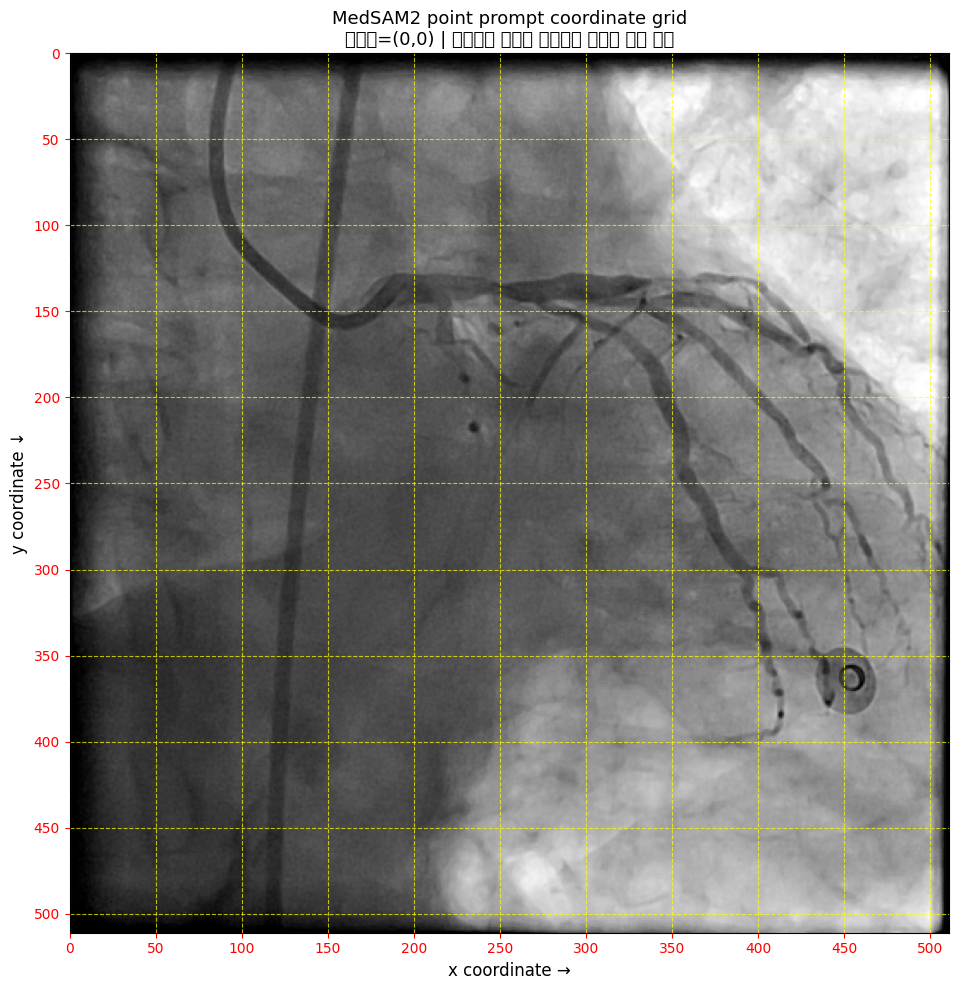

좌표 그리드 저장: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_7_frame_0033_coordinate_grid.png

다음 셀에서 입력할 값:
POINT_X = 관상동맥 내부의 x 좌표
POINT_Y = 관상동맥 내부의 y 좌표

주의: 굵고 길게 보이는 catheter가 아니라, 조영제로 채워진 분지 혈관 내부를 선택하세요.


In [ ]:
#@title 05. 선택 이미지 확인 및 point 좌표 그리드 표시

from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# 1. 앞 셀에서 생성된 이미지 경로 확인
# ============================================================

if "SELECTED_IMAGE_PATH" in globals():
    resolved_image_path = Path(
        SELECTED_IMAGE_PATH
    )

elif "SELECTED_FRAME_PATH" in globals():
    resolved_image_path = Path(
        SELECTED_FRAME_PATH
    )

elif "selected_image_path" in globals():
    resolved_image_path = Path(
        selected_image_path
    )

elif "FRAME_PATH" in globals():
    resolved_image_path = Path(
        FRAME_PATH
    )

else:
    raise NameError(
        "선택 이미지 경로 변수가 없습니다. "
        "03번 셀을 먼저 실행하세요."
    )

assert resolved_image_path.is_file(), (
    "선택 이미지 파일이 존재하지 않습니다: "
    f"{resolved_image_path}"
)


# ============================================================
# 2. 이후 셀에서 사용할 경로 변수명 통일
# ============================================================

SELECTED_IMAGE_PATH = resolved_image_path
SELECTED_FRAME_PATH = resolved_image_path
selected_image_path = resolved_image_path
FRAME_PATH = resolved_image_path

print(
    "선택 이미지:",
    SELECTED_FRAME_PATH,
)


# ============================================================
# 3. 이미지 로드
# ============================================================

selected_image = Image.open(
    SELECTED_FRAME_PATH
).convert("RGB")

image_rgb = np.array(
    selected_image
)

# 뒤 셀 호환용 alias
image_array = image_rgb
selected_image_array = image_rgb

IMAGE_HEIGHT, IMAGE_WIDTH = (
    image_rgb.shape[:2]
)

width = IMAGE_WIDTH
height = IMAGE_HEIGHT

print(
    "이미지 크기:",
    f"{IMAGE_WIDTH} × {IMAGE_HEIGHT}",
)
print(
    "NumPy shape:",
    image_rgb.shape,
)


# ============================================================
# 4. 좌표 그리드 간격 설정
# ============================================================

if max(
    IMAGE_WIDTH,
    IMAGE_HEIGHT,
) <= 512:
    GRID_INTERVAL = 50
else:
    GRID_INTERVAL = 100

x_ticks = np.arange(
    0,
    IMAGE_WIDTH + 1,
    GRID_INTERVAL,
)

y_ticks = np.arange(
    0,
    IMAGE_HEIGHT + 1,
    GRID_INTERVAL,
)


# ============================================================
# 5. 좌표 그리드 시각화
#
# 좌상단 = (0, 0)
# 오른쪽으로 갈수록 x 증가
# 아래쪽으로 갈수록 y 증가
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 10)
)

ax.imshow(
    image_rgb,
    origin="upper",
)

ax.set_xticks(x_ticks)
ax.set_yticks(y_ticks)

ax.grid(
    visible=True,
    color="yellow",
    linestyle="--",
    linewidth=0.8,
    alpha=0.7,
)

ax.tick_params(
    axis="both",
    colors="red",
    labelsize=10,
)

ax.set_xlim(
    0,
    IMAGE_WIDTH - 1,
)

ax.set_ylim(
    IMAGE_HEIGHT - 1,
    0,
)

ax.set_xlabel(
    "x coordinate →",
    fontsize=12,
)

ax.set_ylabel(
    "y coordinate ↓",
    fontsize=12,
)

ax.set_title(
    "MedSAM2 point prompt coordinate grid\n"
    "좌상단=(0,0) | 조영제로 채워진 관상동맥 내부의 점을 선택",
    fontsize=13,
)

plt.tight_layout()


# ============================================================
# 6. 좌표 그리드 결과 저장
# ============================================================

if "RESULTS_DIR" in globals():
    grid_save_dir = Path(
        RESULTS_DIR
    )

elif "PHASE2_ROOT" in globals():
    grid_save_dir = (
        Path(PHASE2_ROOT)
        / "results"
    )

else:
    grid_save_dir = Path(
        "/content/drive/MyDrive/"
        "[MacGyver]최종프로젝트/"
        "03_data/AngioCAD/hyunkyung/"
        "02_medsam2_vessel_segmentation/"
        "results"
    )

grid_save_dir.mkdir(
    parents=True,
    exist_ok=True,
)

COORDINATE_GRID_PATH = (
    grid_save_dir
    / (
        f"patient_{PATIENT_ID:03d}"
        f"_series_{SERIES_ID}"
        f"_{Path(FRAME_NAME).stem}"
        "_coordinate_grid.png"
    )
)

fig.savefig(
    COORDINATE_GRID_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "좌표 그리드 저장:",
    COORDINATE_GRID_PATH,
)


# ============================================================
# 7. 다음 셀 안내
# ============================================================

print()
print(
    "다음 셀에서 입력할 값:"
)
print(
    "POINT_X = 관상동맥 내부의 x 좌표"
)
print(
    "POINT_Y = 관상동맥 내부의 y 좌표"
)
print()
print(
    "주의: 굵고 길게 보이는 catheter가 아니라, "
    "조영제로 채워진 분지 혈관 내부를 선택하세요."
)

입력 이미지 크기: 512 × 512
Positive point: (390, 200)


/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 47197 (\N{HANGUL SYLLABLE ROG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 49353 (\N{HANGUL SYLLABLE SAEG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_761/2972771738.py:261: UserWarning: Glyph 49900 (\N{HANGUL SYLLABLE SIM}) missing from font(s) DejaVu Sans.
  plt.tight_

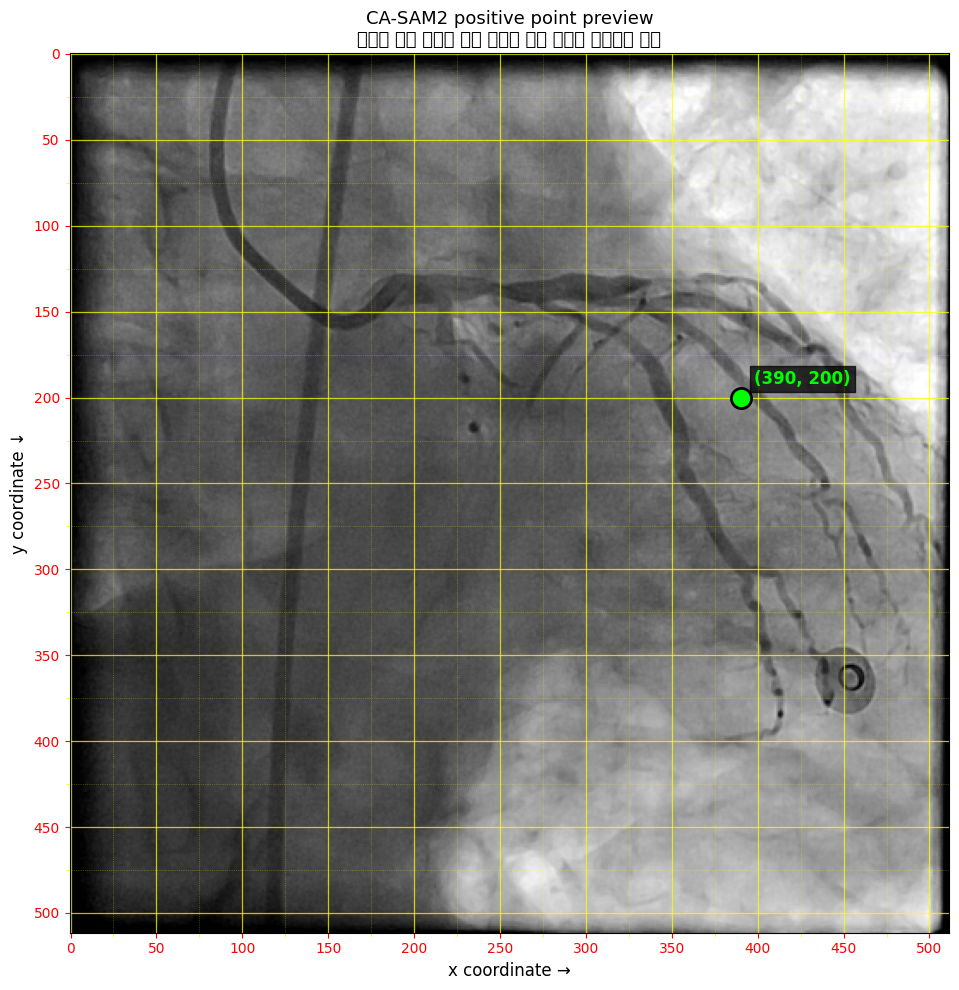

Point preview 저장: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_7_frame_0033_point_390_200.png
Inference dtype: torch.bfloat16

✅ CA-SAM2 추론 완료
Candidate masks shape: (3, 512, 512)
Candidate scores: [0.5977, 0.5273, 0.668]
Score 순서: [2, 0, 1]
Inference seconds: 0.0318

주의: score는 모델 내부 mask 품질 추정값이며 Dice나 실제 정확도가 아닙니다.
초록색 점이 혈관 중심에 정확히 놓였으면 이어서 07번 셀을 실행하세요.


In [ ]:
#@title 06. 격자 위에서 point 확인 후 CA-SAM2 혈관 분할

from pathlib import Path
from contextlib import nullcontext
import time

import numpy as np
import matplotlib.pyplot as plt
import torch


# ============================================================
# 1. 이미지 변수 확인
# ============================================================

if "image_rgb" in globals():
    inference_image = np.asarray(
        image_rgb
    )

elif "image_array" in globals():
    inference_image = np.asarray(
        image_array
    )

elif "selected_image_array" in globals():
    inference_image = np.asarray(
        selected_image_array
    )

elif "selected_image" in globals():
    inference_image = np.asarray(
        selected_image.convert("RGB")
    )

else:
    raise NameError(
        "입력 이미지가 없습니다. "
        "05번 셀을 먼저 실행하세요."
    )

if inference_image.ndim == 2:
    inference_image = np.stack(
        [inference_image] * 3,
        axis=-1,
    )

if inference_image.shape[2] == 4:
    inference_image = (
        inference_image[:, :, :3]
    )

assert (
    inference_image.ndim == 3
    and inference_image.shape[2] == 3
), (
    "입력 이미지는 H×W×3이어야 합니다: "
    f"{inference_image.shape}"
)

if inference_image.dtype != np.uint8:
    inference_image = np.clip(
        inference_image,
        0,
        255,
    ).astype(np.uint8)

image_height, image_width = (
    inference_image.shape[:2]
)

# 후속 셀 호환용 변수
IMAGE_HEIGHT = image_height
IMAGE_WIDTH = image_width
height = image_height
width = image_width

image_rgb = inference_image
image_array = inference_image
selected_image_array = inference_image

print(
    "입력 이미지 크기:",
    f"{image_width} × {image_height}",
)


# ============================================================
# 2. Positive point 설정
#
# 입력값을 바꾼 뒤 반드시 셀을 다시 실행
# ============================================================

POINT_X = 390  #@param {type:"integer"}
POINT_Y = 200  #@param {type:"integer"}

assert 0 <= POINT_X < image_width, (
    f"POINT_X={POINT_X}가 영상 범위를 "
    f"벗어났습니다: 0~{image_width - 1}"
)

assert 0 <= POINT_Y < image_height, (
    f"POINT_Y={POINT_Y}가 영상 범위를 "
    f"벗어났습니다: 0~{image_height - 1}"
)

print(
    "Positive point:",
    (POINT_X, POINT_Y),
)


# ============================================================
# 3. 격자가 표시된 point preview
#
# 노란색 실선: 50 pixel
# 노란색 점선: 25 pixel
# 좌상단: (0, 0)
# ============================================================

MAJOR_GRID_INTERVAL = 50
MINOR_GRID_INTERVAL = 25

major_x_ticks = np.arange(
    0,
    image_width + 1,
    MAJOR_GRID_INTERVAL,
)

major_y_ticks = np.arange(
    0,
    image_height + 1,
    MAJOR_GRID_INTERVAL,
)

minor_x_ticks = np.arange(
    0,
    image_width + 1,
    MINOR_GRID_INTERVAL,
)

minor_y_ticks = np.arange(
    0,
    image_height + 1,
    MINOR_GRID_INTERVAL,
)

fig, ax = plt.subplots(
    figsize=(10, 10)
)

ax.imshow(
    inference_image,
    origin="upper",
)

# Major grid
ax.set_xticks(
    major_x_ticks
)

ax.set_yticks(
    major_y_ticks
)

# Minor grid
ax.set_xticks(
    minor_x_ticks,
    minor=True,
)

ax.set_yticks(
    minor_y_ticks,
    minor=True,
)

ax.grid(
    which="major",
    color="yellow",
    linestyle="-",
    linewidth=0.9,
    alpha=0.75,
)

ax.grid(
    which="minor",
    color="yellow",
    linestyle=":",
    linewidth=0.5,
    alpha=0.45,
)

# 선택 point
ax.scatter(
    [POINT_X],
    [POINT_Y],
    s=210,
    c="lime",
    edgecolors="black",
    linewidths=2,
    marker="o",
    zorder=10,
)

ax.text(
    POINT_X + 8,
    POINT_Y - 8,
    f"({POINT_X}, {POINT_Y})",
    color="lime",
    fontsize=12,
    fontweight="bold",
    zorder=11,
    bbox={
        "facecolor": "black",
        "alpha": 0.75,
        "pad": 3,
    },
)

# 영상 좌표계를 그대로 유지
ax.set_xlim(
    -0.5,
    image_width - 0.5,
)

ax.set_ylim(
    image_height - 0.5,
    -0.5,
)

ax.tick_params(
    axis="both",
    which="major",
    colors="red",
    labelsize=10,
)

ax.tick_params(
    axis="both",
    which="minor",
    length=3,
    colors="yellow",
)

ax.set_xlabel(
    "x coordinate →",
    fontsize=12,
)

ax.set_ylabel(
    "y coordinate ↓",
    fontsize=12,
)

ax.set_title(
    "CA-SAM2 positive point preview\n"
    "초록색 점의 중심이 검게 조영된 혈관 내부와 겹치는지 확인",
    fontsize=13,
)

plt.tight_layout()


# ============================================================
# 4. Point preview 저장
# ============================================================

if "RESULTS_DIR" in globals():
    point_save_dir = Path(
        RESULTS_DIR
    )

elif "PHASE2_ROOT" in globals():
    point_save_dir = (
        Path(PHASE2_ROOT)
        / "results"
    )

else:
    point_save_dir = Path(
        "/content/drive/MyDrive/"
        "[MacGyver]최종프로젝트/"
        "03_data/AngioCAD/hyunkyung/"
        "02_medsam2_vessel_segmentation/"
        "results"
    )

point_save_dir.mkdir(
    parents=True,
    exist_ok=True,
)

patient_id_for_name = int(
    globals().get("PATIENT_ID", 6)
)

series_id_for_name = int(
    globals().get("SERIES_ID", 7)
)

frame_name_for_name = str(
    globals().get(
        "FRAME_NAME",
        "frame_0033.png",
    )
)

POINT_PREVIEW_PATH = (
    point_save_dir
    / (
        f"patient_{patient_id_for_name:03d}"
        f"_series_{series_id_for_name}"
        f"_{Path(frame_name_for_name).stem}"
        f"_point_{POINT_X}_{POINT_Y}.png"
    )
)

fig.savefig(
    POINT_PREVIEW_PATH,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

print(
    "Point preview 저장:",
    POINT_PREVIEW_PATH,
)


# ============================================================
# 5. Predictor 확인
# ============================================================

if "predictor" not in globals():
    if "medsam2_predictor" in globals():
        predictor = medsam2_predictor

    else:
        raise NameError(
            "MedSAM2 predictor가 없습니다. "
            "04번 셀을 먼저 실행하세요."
        )


# ============================================================
# 6. SAM2 prompt 구성
# ============================================================

input_point = np.array(
    [
        [POINT_X, POINT_Y]
    ],
    dtype=np.float32,
)

input_label = np.array(
    [1],
    dtype=np.int32,
)

point_coords = input_point
point_labels = input_label


# ============================================================
# 7. Mixed precision 설정
# ============================================================

if torch.cuda.is_available():
    INFERENCE_DTYPE = (
        torch.bfloat16
        if torch.cuda.is_bf16_supported()
        else torch.float16
    )

    precision_context = torch.autocast(
        device_type="cuda",
        dtype=INFERENCE_DTYPE,
    )

else:
    INFERENCE_DTYPE = torch.float32
    precision_context = nullcontext()

print(
    "Inference dtype:",
    INFERENCE_DTYPE,
)


# ============================================================
# 8. CA-SAM2 추론
# ============================================================

if torch.cuda.is_available():
    torch.cuda.synchronize()

start_time = time.perf_counter()

with torch.inference_mode():
    with precision_context:
        predictor.set_image(
            inference_image
        )

        (
            candidate_masks,
            candidate_scores,
            candidate_logits,
        ) = predictor.predict(
            point_coords=input_point,
            point_labels=input_label,
            multimask_output=True,
        )

if torch.cuda.is_available():
    torch.cuda.synchronize()

inference_seconds = (
    time.perf_counter()
    - start_time
)


# ============================================================
# 9. 결과 정리
# ============================================================

candidate_masks = np.asarray(
    candidate_masks
)

candidate_scores = np.asarray(
    candidate_scores
).reshape(-1)

candidate_logits = np.asarray(
    candidate_logits
)

assert candidate_masks.ndim == 3, (
    "mask가 N×H×W 형식이 아닙니다: "
    f"{candidate_masks.shape}"
)

assert (
    len(candidate_masks)
    == len(candidate_scores)
), (
    "mask 수와 score 수가 다릅니다."
)

# 07번 셀 호환용 변수
masks = candidate_masks
scores = candidate_scores
logits = candidate_logits

score_order = np.argsort(
    candidate_scores
)[::-1]

print()
print(
    "✅ CA-SAM2 추론 완료"
)
print(
    "Candidate masks shape:",
    candidate_masks.shape,
)
print(
    "Candidate scores:",
    [
        round(float(score), 4)
        for score in candidate_scores
    ],
)
print(
    "Score 순서:",
    score_order.tolist(),
)
print(
    "Inference seconds:",
    round(inference_seconds, 4),
)

print()
print(
    "주의: score는 모델 내부 mask 품질 추정값이며 "
    "Dice나 실제 정확도가 아닙니다."
)
print(
    "초록색 점이 혈관 중심에 정확히 놓였으면 "
    "이어서 07번 셀을 실행하세요."
)

Candidate masks: (3, 512, 512)
Candidate scores: [0.5977, 0.5273, 0.668]

=== Candidate statistics ===
Rank 1 | index=2 | score=0.6680 | pixels=9775 | area=0.0373 | point_inside=False | components=10 | largest_component=0.940
Rank 2 | index=0 | score=0.5977 | pixels=11951 | area=0.0456 | point_inside=False | components=17 | largest_component=0.897
Rank 3 | index=1 | score=0.5273 | pixels=7062 | area=0.0269 | point_inside=False | components=8 | largest_component=0.936

임시 선택 candidate index: 2
선택 방법: automatic_highest_score_with_point
선택 candidate score: 0.668


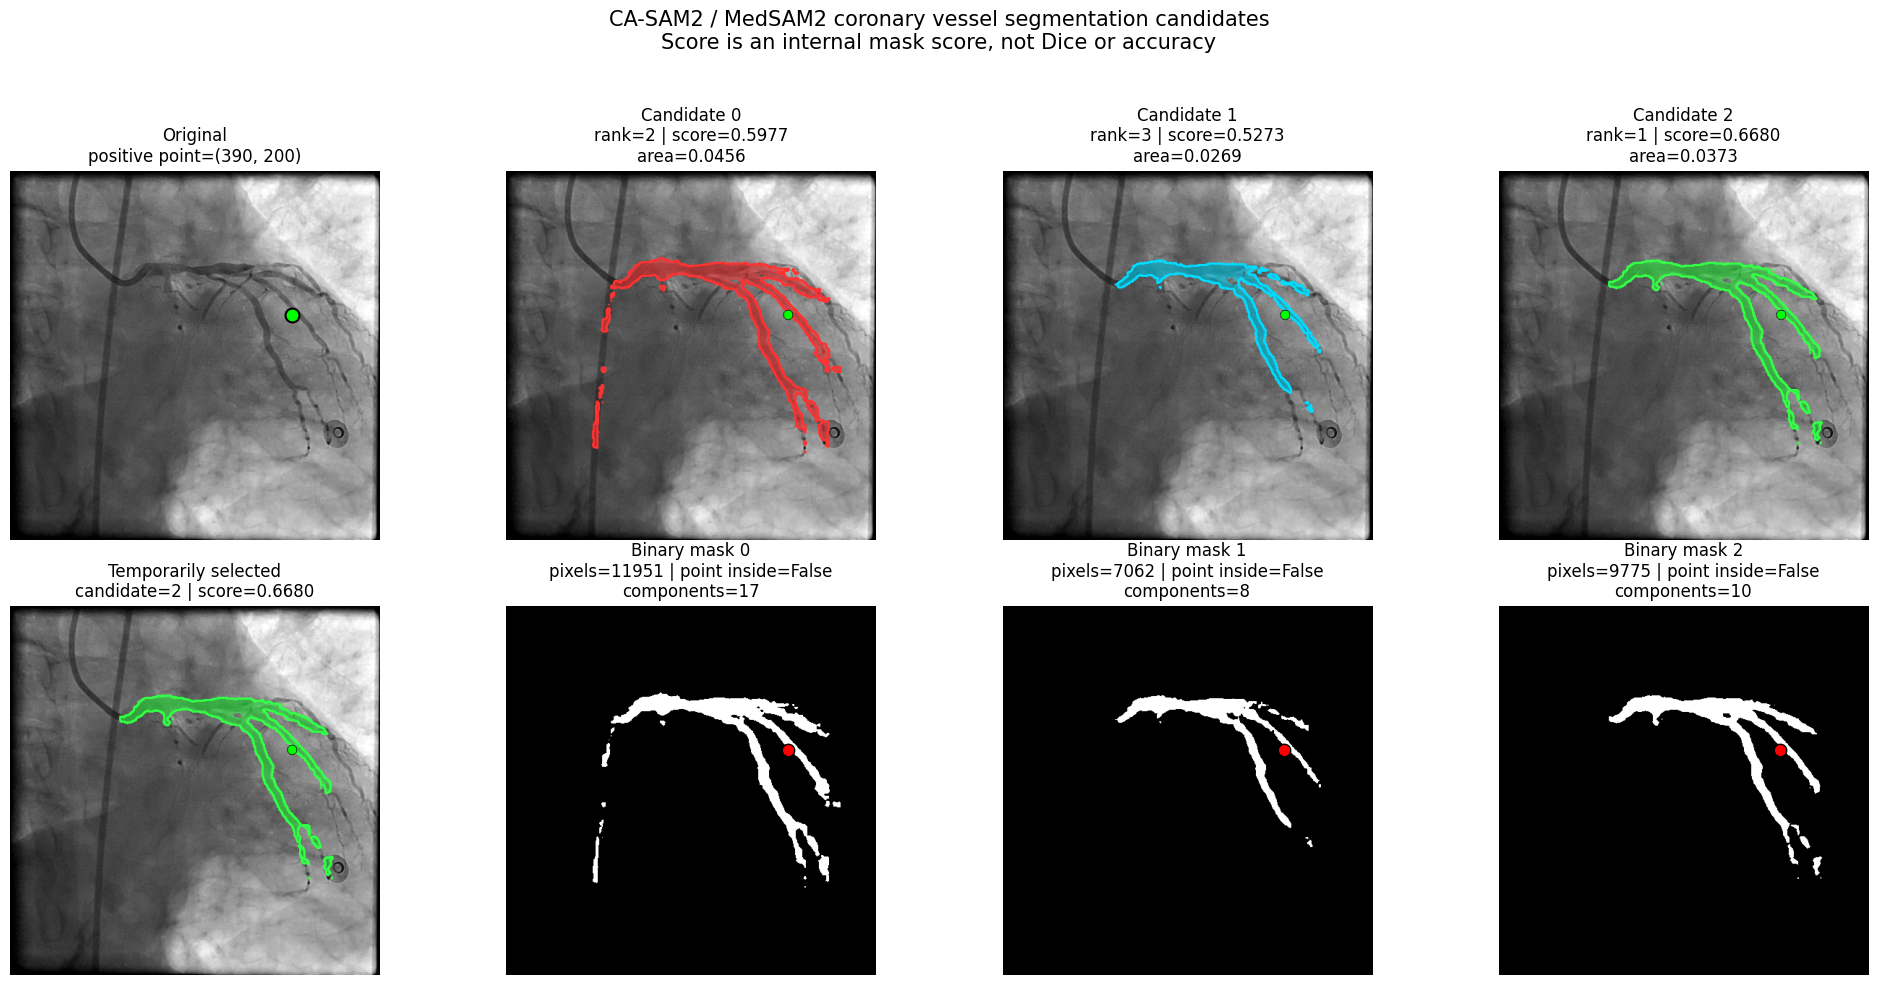


✅ Candidate 비교 및 저장 완료
Comparison: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_7_frame_0033_point_390_200_candidate_comparison.png
Selected mask: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/masks/patient_006_series_7_frame_0033_point_390_200_selected_mask.png
Selected overlay: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/overlays/patient_006_series_7_frame_0033_point_390_200_selected_overlay.png
Candidate arrays: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_7_frame_0033_point_390_200_candidate_arrays.npz
Result JSON: /content/drive/MyDrive/[MacGyver]최종프로젝트/03_data/AngioCAD/hyunkyung/02_medsam2_vessel_segmentation/results/patient_006_series_7_frame_0033_point_390_200_result.json

다음 

In [ ]:
#@title 07. CA-SAM2 candidate mask 비교 및 결과 저장

from pathlib import Path
import json

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


# ============================================================
# 1. 06번 셀 결과 확인
# ============================================================

if "candidate_masks" in globals():
    all_masks = np.asarray(
        candidate_masks
    )

elif "masks" in globals():
    all_masks = np.asarray(
        masks
    )

else:
    raise NameError(
        "Candidate mask가 없습니다. "
        "06번 셀을 먼저 실행하세요."
    )


if "candidate_scores" in globals():
    all_scores = np.asarray(
        candidate_scores
    ).reshape(-1)

elif "scores" in globals():
    all_scores = np.asarray(
        scores
    ).reshape(-1)

else:
    raise NameError(
        "Candidate score가 없습니다. "
        "06번 셀을 먼저 실행하세요."
    )


if "inference_image" in globals():
    original_image = np.asarray(
        inference_image
    )

elif "image_rgb" in globals():
    original_image = np.asarray(
        image_rgb
    )

else:
    raise NameError(
        "원본 이미지가 없습니다. "
        "05번 또는 06번 셀을 먼저 실행하세요."
    )


# ============================================================
# 2. 배열 형식 보정
# ============================================================

if all_masks.ndim == 4:
    if all_masks.shape[1] == 1:
        all_masks = all_masks[:, 0]

    elif all_masks.shape[-1] == 1:
        all_masks = all_masks[..., 0]

assert all_masks.ndim == 3, (
    "mask 배열은 N×H×W 형식이어야 합니다: "
    f"{all_masks.shape}"
)

assert len(all_masks) == len(all_scores), (
    "mask와 score의 개수가 다릅니다: "
    f"{len(all_masks)} vs {len(all_scores)}"
)

image_height, image_width = (
    original_image.shape[:2]
)

binary_masks = []

for candidate_mask in all_masks:
    candidate_mask = np.asarray(
        candidate_mask
    )

    if candidate_mask.shape != (
        image_height,
        image_width,
    ):
        candidate_mask = cv2.resize(
            candidate_mask.astype(
                np.float32
            ),
            (
                image_width,
                image_height,
            ),
            interpolation=cv2.INTER_NEAREST,
        )

    binary_masks.append(
        candidate_mask > 0
    )

binary_masks = np.stack(
    binary_masks,
    axis=0,
)

# 후속 셀 호환용 변수
candidate_masks = binary_masks
candidate_scores = all_scores
masks = binary_masks
scores = all_scores

print(
    "Candidate masks:",
    binary_masks.shape,
)
print(
    "Candidate scores:",
    [
        round(float(score), 4)
        for score in all_scores
    ],
)


# ============================================================
# 3. 출력 폴더 설정
# ============================================================

if "PHASE2_ROOT" in globals():
    phase2_root = Path(
        PHASE2_ROOT
    )

else:
    phase2_root = Path(
        "/content/drive/MyDrive/"
        "[MacGyver]최종프로젝트/"
        "03_data/AngioCAD/hyunkyung/"
        "02_medsam2_vessel_segmentation"
    )

mask_save_dir = (
    Path(MASK_DIR)
    if "MASK_DIR" in globals()
    else phase2_root / "masks"
)

overlay_save_dir = (
    Path(OVERLAY_DIR)
    if "OVERLAY_DIR" in globals()
    else phase2_root / "overlays"
)

result_save_dir = (
    Path(RESULTS_DIR)
    if "RESULTS_DIR" in globals()
    else phase2_root / "results"
)

for directory in [
    mask_save_dir,
    overlay_save_dir,
    result_save_dir,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. 파일명 prefix
# ============================================================

patient_id_for_name = int(
    globals().get("PATIENT_ID", 6)
)

series_id_for_name = int(
    globals().get("SERIES_ID", 7)
)

frame_name_for_name = str(
    globals().get(
        "FRAME_NAME",
        "frame_0033.png",
    )
)

frame_stem = Path(
    frame_name_for_name
).stem

result_prefix = (
    f"patient_{patient_id_for_name:03d}"
    f"_series_{series_id_for_name}"
    f"_{frame_stem}"
    f"_point_{POINT_X}_{POINT_Y}"
)


# ============================================================
# 5. Overlay 생성 함수
# ============================================================

candidate_colors_rgb = [
    (255, 50, 50),      # candidate 0: red
    (0, 220, 255),      # candidate 1: cyan
    (50, 255, 70),      # candidate 2: green
    (255, 80, 255),
    (255, 210, 0),
]


def make_mask_overlay(
    image,
    mask,
    color_rgb,
    alpha=0.55,
):
    overlay = image.copy().astype(
        np.float32
    )

    color_array = np.array(
        color_rgb,
        dtype=np.float32,
    )

    overlay[mask] = (
        (1.0 - alpha) * overlay[mask]
        + alpha * color_array
    )

    overlay = np.clip(
        overlay,
        0,
        255,
    ).astype(np.uint8)

    contours, _ = cv2.findContours(
        mask.astype(np.uint8),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE,
    )

    # OpenCV용 RGB 색상
    cv2.drawContours(
        overlay,
        contours,
        contourIdx=-1,
        color=color_rgb,
        thickness=2,
    )

    # Positive point
    cv2.circle(
        overlay,
        center=(
            int(POINT_X),
            int(POINT_Y),
        ),
        radius=6,
        color=(0, 255, 0),
        thickness=-1,
    )

    cv2.circle(
        overlay,
        center=(
            int(POINT_X),
            int(POINT_Y),
        ),
        radius=7,
        color=(0, 0, 0),
        thickness=1,
    )

    return overlay


# ============================================================
# 6. 각 candidate 통계 계산
# ============================================================

candidate_statistics = []
candidate_overlays = []

for candidate_index, (
    candidate_mask,
    candidate_score,
) in enumerate(
    zip(
        binary_masks,
        all_scores,
    )
):
    mask_pixels = int(
        candidate_mask.sum()
    )

    area_ratio = float(
        mask_pixels
        / (
            image_height
            * image_width
        )
    )

    point_inside = bool(
        candidate_mask[
            int(POINT_Y),
            int(POINT_X),
        ]
    )

    number_of_labels, _, stats, _ = (
        cv2.connectedComponentsWithStats(
            candidate_mask.astype(
                np.uint8
            ),
            connectivity=8,
        )
    )

    component_count = max(
        0,
        number_of_labels - 1,
    )

    if component_count > 0:
        largest_component_pixels = int(
            stats[
                1:,
                cv2.CC_STAT_AREA,
            ].max()
        )
    else:
        largest_component_pixels = 0

    largest_component_ratio = float(
        largest_component_pixels
        / max(1, mask_pixels)
    )

    color_rgb = candidate_colors_rgb[
        candidate_index
        % len(candidate_colors_rgb)
    ]

    candidate_overlay = make_mask_overlay(
        original_image,
        candidate_mask,
        color_rgb,
    )

    candidate_overlays.append(
        candidate_overlay
    )

    candidate_statistics.append(
        {
            "candidate_index": int(
                candidate_index
            ),
            "display_rank": None,
            "score": float(
                candidate_score
            ),
            "mask_pixels": mask_pixels,
            "area_ratio": area_ratio,
            "point_inside_mask": point_inside,
            "connected_components": int(
                component_count
            ),
            "largest_component_pixels": (
                largest_component_pixels
            ),
            "largest_component_ratio": (
                largest_component_ratio
            ),
        }
    )


# ============================================================
# 7. Score 순위 지정
# ============================================================

score_order = np.argsort(
    all_scores
)[::-1]

for rank, candidate_index in enumerate(
    score_order,
    start=1,
):
    candidate_statistics[
        int(candidate_index)
    ]["display_rank"] = int(rank)


print()
print(
    "=== Candidate statistics ==="
)

for candidate_index in score_order:
    stat = candidate_statistics[
        int(candidate_index)
    ]

    print(
        f"Rank {stat['display_rank']} | "
        f"index={stat['candidate_index']} | "
        f"score={stat['score']:.4f} | "
        f"pixels={stat['mask_pixels']} | "
        f"area={stat['area_ratio']:.4f} | "
        f"point_inside={stat['point_inside_mask']} | "
        f"components={stat['connected_components']} | "
        f"largest_component="
        f"{stat['largest_component_ratio']:.3f}"
    )


# ============================================================
# 8. 임시 자동 선택
#
# - point를 포함하는 mask 중 score 최고
# - 없으면 전체 score 최고
#
# 그림을 보고 다른 후보가 더 적절하면
# MANUAL_CANDIDATE_INDEX를 0, 1, 2 중 하나로 변경하고
# 이 셀을 다시 실행
# ============================================================

eligible_indices = [
    index
    for index, stat
    in enumerate(candidate_statistics)
    if (
        stat["point_inside_mask"]
        and stat["mask_pixels"] > 0
    )
]

if eligible_indices:
    auto_selected_index = max(
        eligible_indices,
        key=lambda index: float(
            all_scores[index]
        ),
    )

else:
    auto_selected_index = int(
        np.argmax(all_scores)
    )

# -1이면 자동 선택
# 0, 1, 2를 입력하면 해당 candidate를 직접 선택
MANUAL_CANDIDATE_INDEX = -1  #@param {type:"integer"}

if MANUAL_CANDIDATE_INDEX == -1:
    selected_candidate_index = int(
        auto_selected_index
    )
    selection_method = (
        "automatic_highest_score_with_point"
    )

else:
    assert (
        0
        <= MANUAL_CANDIDATE_INDEX
        < len(binary_masks)
    ), (
        "MANUAL_CANDIDATE_INDEX는 "
        f"-1 또는 0~{len(binary_masks)-1}이어야 합니다."
    )

    selected_candidate_index = int(
        MANUAL_CANDIDATE_INDEX
    )

    selection_method = (
        "manual_visual_selection"
    )

selected_mask = binary_masks[
    selected_candidate_index
]

selected_overlay = candidate_overlays[
    selected_candidate_index
]

selected_score = float(
    all_scores[
        selected_candidate_index
    ]
)

print()
print(
    "임시 선택 candidate index:",
    selected_candidate_index,
)
print(
    "선택 방법:",
    selection_method,
)
print(
    "선택 candidate score:",
    round(selected_score, 4),
)


# ============================================================
# 9. Candidate 비교 figure
# ============================================================

candidate_count = len(
    binary_masks
)

figure_columns = (
    candidate_count + 1
)

fig, axes = plt.subplots(
    2,
    figure_columns,
    figsize=(
        5 * figure_columns,
        10,
    ),
)

# Original
axes[0, 0].imshow(
    original_image
)

axes[0, 0].scatter(
    [POINT_X],
    [POINT_Y],
    s=100,
    c="lime",
    edgecolors="black",
    linewidths=1.5,
)

axes[0, 0].set_title(
    "Original\n"
    f"positive point=({POINT_X}, {POINT_Y})"
)

axes[0, 0].axis("off")

# Selected overlay
axes[1, 0].imshow(
    selected_overlay
)

axes[1, 0].set_title(
    "Temporarily selected\n"
    f"candidate={selected_candidate_index} | "
    f"score={selected_score:.4f}"
)

axes[1, 0].axis("off")


for column_index in range(
    candidate_count
):
    stat = candidate_statistics[
        column_index
    ]

    axes[
        0,
        column_index + 1,
    ].imshow(
        candidate_overlays[
            column_index
        ]
    )

    axes[
        0,
        column_index + 1,
    ].set_title(
        f"Candidate {column_index}\n"
        f"rank={stat['display_rank']} | "
        f"score={stat['score']:.4f}\n"
        f"area={stat['area_ratio']:.4f}"
    )

    axes[
        0,
        column_index + 1,
    ].axis("off")

    axes[
        1,
        column_index + 1,
    ].imshow(
        binary_masks[
            column_index
        ],
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    point_color = (
        "lime"
        if stat["point_inside_mask"]
        else "red"
    )

    axes[
        1,
        column_index + 1,
    ].scatter(
        [POINT_X],
        [POINT_Y],
        s=80,
        c=point_color,
        edgecolors="black",
        linewidths=1,
    )

    axes[
        1,
        column_index + 1,
    ].set_title(
        f"Binary mask {column_index}\n"
        f"pixels={stat['mask_pixels']} | "
        f"point inside="
        f"{stat['point_inside_mask']}\n"
        f"components="
        f"{stat['connected_components']}"
    )

    axes[
        1,
        column_index + 1,
    ].axis("off")


fig.suptitle(
    "CA-SAM2 / MedSAM2 coronary vessel segmentation candidates\n"
    "Score is an internal mask score, not Dice or accuracy",
    fontsize=15,
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)


# ============================================================
# 10. 개별 mask 및 overlay 저장
# ============================================================

candidate_file_records = []

for candidate_index in range(
    candidate_count
):
    candidate_mask_path = (
        mask_save_dir
        / (
            f"{result_prefix}"
            f"_candidate_{candidate_index}"
            "_mask.png"
        )
    )

    candidate_overlay_path = (
        overlay_save_dir
        / (
            f"{result_prefix}"
            f"_candidate_{candidate_index}"
            "_overlay.png"
        )
    )

    Image.fromarray(
        (
            binary_masks[
                candidate_index
            ].astype(np.uint8)
            * 255
        )
    ).save(
        candidate_mask_path
    )

    Image.fromarray(
        candidate_overlays[
            candidate_index
        ]
    ).save(
        candidate_overlay_path
    )

    candidate_file_records.append(
        {
            "candidate_index": int(
                candidate_index
            ),
            "mask_path": str(
                candidate_mask_path
            ),
            "overlay_path": str(
                candidate_overlay_path
            ),
        }
    )


# ============================================================
# 11. 선택 결과 저장
# ============================================================

COMPARISON_FIGURE_PATH = (
    result_save_dir
    / (
        f"{result_prefix}"
        "_candidate_comparison.png"
    )
)

SELECTED_MASK_PATH = (
    mask_save_dir
    / (
        f"{result_prefix}"
        "_selected_mask.png"
    )
)

SELECTED_OVERLAY_PATH = (
    overlay_save_dir
    / (
        f"{result_prefix}"
        "_selected_overlay.png"
    )
)

CANDIDATE_ARRAY_PATH = (
    result_save_dir
    / (
        f"{result_prefix}"
        "_candidate_arrays.npz"
    )
)

RESULT_JSON_PATH = (
    result_save_dir
    / (
        f"{result_prefix}"
        "_result.json"
    )
)

fig.savefig(
    COMPARISON_FIGURE_PATH,
    dpi=180,
    bbox_inches="tight",
)

Image.fromarray(
    selected_mask.astype(
        np.uint8
    ) * 255
).save(
    SELECTED_MASK_PATH
)

Image.fromarray(
    selected_overlay
).save(
    SELECTED_OVERLAY_PATH
)

npz_payload = {
    "candidate_masks": (
        binary_masks.astype(
            np.uint8
        )
    ),
    "candidate_scores": (
        all_scores.astype(
            np.float32
        )
    ),
    "selected_candidate_index": (
        np.array(
            selected_candidate_index,
            dtype=np.int32,
        )
    ),
    "positive_point_xy": (
        np.array(
            [POINT_X, POINT_Y],
            dtype=np.int32,
        )
    ),
}

if "candidate_logits" in globals():
    npz_payload["candidate_logits"] = (
        np.asarray(
            candidate_logits
        ).astype(np.float32)
    )

np.savez_compressed(
    CANDIDATE_ARRAY_PATH,
    **npz_payload,
)


result_record = {
    "experiment": (
        "CA-SAM2 manual point vessel segmentation"
    ),
    "patient_id": patient_id_for_name,
    "series_id": series_id_for_name,
    "frame_name": frame_name_for_name,
    "input_image": str(
        globals().get(
            "SELECTED_IMAGE_PATH",
            globals().get(
                "SELECTED_FRAME_PATH",
                "",
            ),
        )
    ),
    "model_repo": str(
        globals().get(
            "MODEL_REPO_ID",
            "Elakiya17/CA-SAM2",
        )
    ),
    "checkpoint": str(
        globals().get(
            "MODEL_CHECKPOINT_PATH",
            "",
        )
    ),
    "model_config": str(
        globals().get(
            "MODEL_CONFIG",
            "",
        )
    ),
    "positive_point_xy": [
        int(POINT_X),
        int(POINT_Y),
    ],
    "candidate_statistics": (
        candidate_statistics
    ),
    "auto_selected_candidate_index": int(
        auto_selected_index
    ),
    "selected_candidate_index": int(
        selected_candidate_index
    ),
    "selection_method": selection_method,
    "selected_score": selected_score,
    "inference_seconds": float(
        globals().get(
            "inference_seconds",
            -1,
        )
    ),
    "files": {
        "comparison_figure": str(
            COMPARISON_FIGURE_PATH
        ),
        "selected_mask": str(
            SELECTED_MASK_PATH
        ),
        "selected_overlay": str(
            SELECTED_OVERLAY_PATH
        ),
        "candidate_arrays": str(
            CANDIDATE_ARRAY_PATH
        ),
        "candidates": (
            candidate_file_records
        ),
    },
    "evaluation_note": (
        "AngioCAD에는 이 영상의 pixel-level vessel "
        "ground-truth가 없으므로 본 결과는 qualitative "
        "evaluation이다. Candidate score는 Dice 또는 "
        "임상적 정확도가 아니다."
    ),
}

with open(
    RESULT_JSON_PATH,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        result_record,
        file,
        indent=2,
        ensure_ascii=False,
    )

plt.show()


# ============================================================
# 12. 최종 출력
# ============================================================

print()
print(
    "✅ Candidate 비교 및 저장 완료"
)
print(
    "Comparison:",
    COMPARISON_FIGURE_PATH,
)
print(
    "Selected mask:",
    SELECTED_MASK_PATH,
)
print(
    "Selected overlay:",
    SELECTED_OVERLAY_PATH,
)
print(
    "Candidate arrays:",
    CANDIDATE_ARRAY_PATH,
)
print(
    "Result JSON:",
    RESULT_JSON_PATH,
)

print()
print(
    "다음 확인 기준:"
)
print(
    "1. mask가 가느다란 관상동맥 형태를 따르는가?"
)
print(
    "2. catheter, 배경, 심장 전체를 크게 덮지 않는가?"
)
print(
    "3. positive point가 mask 안에 포함되는가?"
)
print(
    "4. score가 높더라도 형태가 틀리면 선택하지 않는다."
)